In [1]:
notes = '''This copy is featured with initial gamma = 0.3.\n
We set f_opt_kh = 1, use_a = True, and L1_regularization = 0, so it is not working.\n
We use warmup_exponential_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 0.2.
In this copy, we train 50000 epoches. '''
print(notes)

This copy is featured with initial gamma = 0.3.

We set f_opt_kh = 1, use_a = True, and L1_regularization = 0, so it is not working.

We use warmup_exponential_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 0.2.
In this copy, we train 50000 epoches. 


In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from minmax_opt_class_mgnn import MinMaxOptProb

import os
os.environ['ENABLE_PJRT_COMPATIBILITY'] = '1'

jax.config.update('jax_platform_name', 'cpu')
os.environ['OMP_NUM_THREADS'] = str(os.cpu_count())

In [3]:
eps0 = 1e-4
def smooth_sign(x, eps = eps0):
    return 2*jax.nn.sigmoid(x/eps)-1

# def u0(x):
#     return 0.5 * (smooth_sign(x - 0.4) - smooth_sign(x - 0.6))

# Define boundary and initial conditions
def u0(x):
    # return 2*smooth_sign(x) - 1
    return -jnp.sign(x)
    # return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 1

# Boundary at x=1
def u2(x):
    return -1

def res_visc(u_quad, u_t, u_x, u_xx, nu, u_exact=0):
    return u_t + (u_quad**2)*u_x - nu*u_xx

def res(u_quad, u_t, u_x):
    return u_t + (u_quad**2)*u_x

# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=8,
    N_x=32,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    project='minmax_mgnn_burgers_inti_sin',
    notes=notes,
    L1_regularization = 0.0,
    sampling_method = 'normal',
    hidden_dims_list=[(40, 40, 40, 40)],
    init_lrs=[1e-3, 1e-3, 1e-3, 1e-3], grade_epochs=[50000, 50000, 50000, 50000], decay_rates=[1e-3, 1e-3, 1e-3, 1e-3], init_lr_stage2=1e-3, epoch_stage2=100000, decay_rate_stage2=1e-3,
    seed=0, sigma=0.2,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,
    N_perturb = 10000,
    f_adaptive_weight = 10000,
    f_opt_kh=1,
    total_grade=1, k=0,
)

In [4]:
optProb.train_process_stage1()


Starting Train Stage with MGDL


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Stage 1: Sequential Grade Training

Training Grade 0
Nt: 512, losses_all shape: (512,)
The gamma of 1th trials is 0.3.
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Grade 0, Gamma 0.3, Iter 0, loss_eqn: 0.07901198, loss_eqn_from_kh: -0.19802678, loss_ibc: 2.44860315
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (512,)
Nt: 512, losses_all shape: (51

KeyboardInterrupt: 

In [ ]:
optProb.train_process_stage2()

In [ ]:
from my_helpers import plot_u_theta
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0, ts=[0.1*i for i in range(11)])  # Plot initial model state


In [ ]:
params = optProb.model.mlps[0].params
optProb.loss_fn_ibc(params)

In [8]:
optProb.pwp.triangles.shape

(512, 3, 2)

In [ ]:
list(params)[0]

In [ ]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = os.path.join('..', 'data', f'train_model_{timestamp}.pkl')

In [ ]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
model_path = os.path.join('data', f'train_model_{timestamp}.pkl')
optProb.save_model(model_path)
print(f"Train model saved to {model_path}")

In [ ]:
optProb.save_model(model_path)

In [ ]:
os.makedirs(os.path.dirname(model_path), exist_ok=True)

In [ ]:
model_path = os.path.join('data', f'train_model_{timestamp}.pkl')

In [ ]:
import matplotlib.pyplot as plt
import jax.numpy as jnp

def plot_u_theta(model, params=None, M_t=100, M_x=100, t_min=0.0, t_max=1.0, x_min=0.0, x_max=1.0):
    """
    Plot the neural network function u_theta over a specified domain [t_min, t_max] x [x_min, x_max],
    and include a 1D plot of u_theta at t = t_max.

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 100).
        M_x: Number of grid points in the x-direction (default: 100).
        t_min: Minimum value for t (default: 0.0).
        t_max: Maximum value for t (default: 1.0).
        x_min: Minimum value for x (default: 0.0).
        x_max: Maximum value for x (default: 1.0).
    """
    # Create a grid for t and x over the specified ranges
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for batch evaluation
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Evaluate u_theta on the grid points
    if params is None:
        u_values = model.forward(tx_points)
    else:
        u_values = model(params, tx_points)  # Shape: (M_t * M_x, 1)
    u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # 2D color mesh plot
    pcm = ax1.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
    fig.colorbar(pcm, ax=ax1, label='$u_\\theta(t, x)$')
    ax1.set_xlabel('x')
    ax1.set_ylabel('t')
    ax1.set_title('Neural Network Function $u_\\theta$')

    # 1D plot at t = t_max
    ax2.plot(x_grid, u_values[-1, :])
    ax2.set_xlabel('x')
    ax2.set_ylabel('$u_\\theta(t_{max}, x)$')
    ax2.set_title(f'Neural Network Function at t = {t_max}')

    # Adjust layout and display
    plt.tight_layout()
    plt.show()

In [ ]:
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot initial model state


In [ ]:
print(os.environ.get('ENABLE_PJRT_COMPATIBILITY'))

In [26]:
A_all.shape

(512, 3, 3)

In [25]:
u_values_all.shape

(512, 3)

In [55]:
params = optProb.model.mlps[0].params
Nt = optProb.pwp.N_elements
vertices_all = optProb.pwp.triangles
u_values_all = optProb.u_eval(params, vertices_all.reshape(-1, 2)).reshape(Nt, 3)
A_all = jnp.stack([jnp.ones((Nt, 3)), vertices_all[:, :, 0], vertices_all[:, :, 1]], axis=-1)
init_coeffs_all = jnp.linalg.solve(A_all, u_values_all[..., None]).squeeze(-1)

In [56]:
current_key = jax.random.PRNGKey(0)
key, current_key = jax.random.split(current_key)
keys = jax.random.split(key, Nt)
perturbations_all = vmap(lambda k: 0.2 * jax.random.normal(k, (1000, 3)))(keys)

In [58]:
losses_all = vmap(optProb.loss_kh_per_elem, in_axes=(0, 0, None))(jnp.arange(Nt), perturbed_coeffs_all, params)
best_indices = jnp.argmax(losses_all, axis=1)
loss_eqn = jnp.sum(losses_all[:, best_indices])

In [45]:
%timeit perturbations_all = vmap(lambda k: 0.2 * jax.random.normal(k, (10000, 3)))(keys)
loss_eqn = jnp.sum(losses_all[:, best_indices])

121 ms ± 3.67 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [46]:
@vmap
def gen_pert(key):
    return 0.2 * jax.random.normal(key, (10000, 3))

In [48]:
perturbations_all = gen_pert(keys)

In [49]:
perturbations_all.shape

(512, 10000, 3)

In [53]:
%timeit perturbed_coeffs_all = init_coeffs_all[:, None, :] + perturbations_all

5.45 ms ± 217 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [61]:
best_indices

Array([   0,    0,    1,    2,    1,    0,    1,    0,    0,    0,    1,
          1,    0,    1,    1,    0,    0,    4,    0,    2,    3,    0,
          3,    1,    1,    2,    0,    0,    2,    0,    0,    0,    2,
          0,    0,    2,    2,    1,    7,    0,    0,    0,    4,    1,
          1,    0,    1,    1,  515,  114,  230,   28,  447,  380,  534,
        617,  193,  790,    0,  118,  461,  744,    1,    2,    1,    3,
          0,    0,    0,    2,    1,    1,    2,    1,    1,    0,    0,
          2,    4,    8,    4,    1,    1,    1,    0,    0,    1,    0,
          0,    5,    0,    2,    2,    3,    1,    0,    0,    5,    7,
          0,    0,   14,    1,    1,    0,    2,    0,    4,    2,    3,
          0,    0,    0,    0,    6,    0,    0,    2,    1,    1,    0,
          0,    2,    0, 1214, 2331, 1509, 1204,    0,    0,    0,    0,
          0,    7,    0,    0,    1,    3,    1,    2,    0,    0,    1,
          0,    0,    0,    0,    1,    0,    0,   

In [62]:
losses_all.shape

(512, 10000)

In [72]:
losses_all[0]

Array([ 0.00023935, -0.00023935,  0.00023935, ...,  0.00023935,
        0.00023935, -0.00023935], dtype=float32)

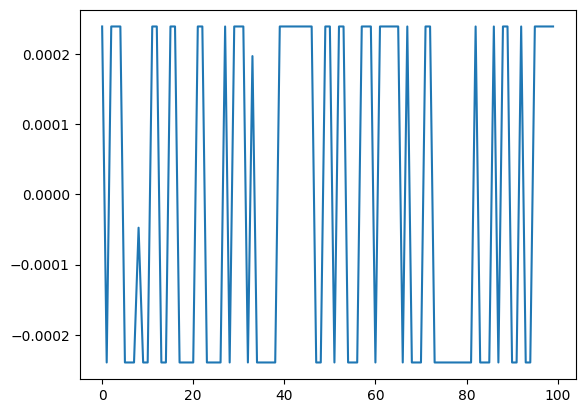

In [73]:
plt.plot(losses_all[0,:100])

In [77]:
tri_idx = 0
optProb.pwp.quad_points_tri[tri_idx]

Array([[ 0.     , -1.     ],
       [ 0.03125, -1.     ],
       [ 0.     , -0.96875],
       [ 0.03125, -1.     ],
       [ 0.0625 , -1.     ],
       [ 0.03125, -0.96875],
       [ 0.     , -0.96875],
       [ 0.03125, -0.96875],
       [ 0.     , -0.9375 ],
       [ 0.03125, -1.     ],
       [ 0.03125, -0.96875],
       [ 0.     , -0.96875]], dtype=float32)

In [78]:
optProb.pwp.quad_weights_tri[tri_idx].flatten()

Array([0.00016276, 0.00016276, 0.00016276, 0.00016276, 0.00016276,
       0.00016276, 0.00016276, 0.00016276, 0.00016276, 0.00016276,
       0.00016276, 0.00016276], dtype=float32)

In [79]:
2/32

0.0625

In [80]:
optProb.pwp.quad_points_tri[tri_idx].shape

(12, 2)